# Convolution from Scratch
For input height $H$, width $W$, kernel height $K_h$, width $K_w$, padding $p$, and stride $s$:

$$H_{out}=\left\lfloor\frac{H+2p-K_h}{s}\right\rfloor+1,\qquad W_{out}=\left\lfloor\frac{W+2p-K_w}{s}\right\rfloor+1.$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def conv2d_scratch(x, kernel, stride=1, padding=0):
    x = np.asarray(x, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    if x.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Input and kernel must be 2D arrays")
    if not isinstance(stride, (int, np.integer)) or stride < 1:
        raise ValueError("stride must be a positive integer")
    if not isinstance(padding, (int, np.integer)) or padding < 0:
        raise ValueError("padding must be a nonnegative integer")
    padded = np.pad(x, padding, mode="constant")
    kh, kw = kernel.shape
    h, w = padded.shape
    if kh > h or kw > w:
        raise ValueError("Kernel cannot exceed padded input dimensions")
    oh = (h - kh) // stride + 1
    ow = (w - kw) // stride + 1
    result = np.zeros((oh, ow), dtype=float)
    for i in range(oh):
        for j in range(ow):
            window = padded[i*stride:i*stride+kh, j*stride:j*stride+kw]
            result[i, j] = np.sum(window * kernel)
    return result

X = np.array([[9,7,2,4,8],[4,8,7,3,1],[7,2,4,8,7],[2,4,8,7,3]])
K = np.array([[1,3,6],[2,4,8],[3,5,9]])
print('Original input:', X.shape, 'kernel:', K.shape)
print('Output (stride=1, padding=0):\n', conv2d_scratch(X, K))


Original input: (4, 5) kernel: (3, 3)
Output (stride=1, padding=0):
 [[205. 203. 211.]
 [222. 246. 204.]]


## Interactive convolution explorer

Install `ipywidgets` 


In [4]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [15]:
# import sys
# print(sys.executable)
# print(sys.version)

In [8]:
%pip install --upgrade ipywidgets jupyterlab_widgets widgetsnbextension

Note: you may need to restart the kernel to use updated packages.


In [10]:
import ipywidgets as widgets
from IPython.display import display

slider = widgets.IntSlider(
    value=1,
    min=1,
    max=5,
    description="Stride"
)

display(slider)

IntSlider(value=1, description='Stride', max=5, min=1)

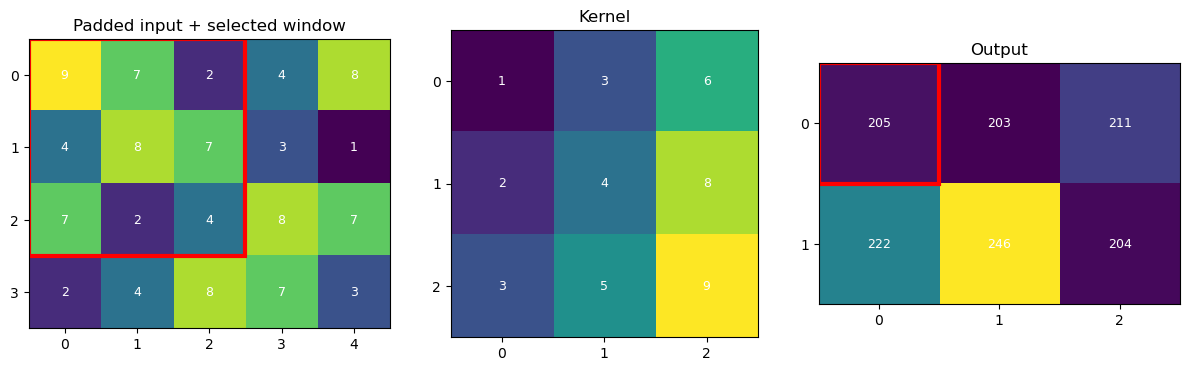

Output shape: (2, 3); selected y[0,0] = sum(window × kernel) = 205


interactive(children=(IntSlider(value=1, description='Stride', max=3, min=1), IntSlider(value=0, description='…

In [12]:
stride_control = widgets.IntSlider(value=1, min=1, max=3, description='Stride')
padding_control = widgets.IntSlider(value=0, min=0, max=3, description='Padding')
row_control = widgets.IntSlider(value=0, min=0, max=6, description='Output row')
col_control = widgets.IntSlider(value=0, min=0, max=6, description='Output col')
kernel_control = widgets.Dropdown(options=['Original', 'All ones', 'Edge detector'], value='Original', description='Kernel')

def explore(stride, padding, output_row, output_col, kernel_choice):
    kernels = {'Original': K, 'All ones': np.ones((3,3)),
               'Edge detector': np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]])}
    kernel = kernels[kernel_choice]
    y = conv2d_scratch(X, kernel, stride, padding)
    padded = np.pad(X, padding)
    i, j = min(output_row, y.shape[0]-1), min(output_col, y.shape[1]-1)
    kh, kw = kernel.shape
    r, c = i*stride, j*stride
    window = padded[r:r+kh, c:c+kw]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
    for ax, data, title in zip(axes, [padded, kernel, y],
                               ['Padded input + selected window', 'Kernel', 'Output']):
        ax.imshow(data, cmap='viridis', aspect='equal')
        ax.set_title(title)
        ax.set_xticks(range(data.shape[1])); ax.set_yticks(range(data.shape[0]))
        for a in range(data.shape[0]):
            for b in range(data.shape[1]):
                ax.text(b, a, f'{data[a,b]:g}', ha='center', va='center',
                        color='white', fontsize=9)
    from matplotlib.patches import Rectangle
    axes[0].add_patch(Rectangle((c-.5,r-.5),kw,kh,fill=False,edgecolor='red',linewidth=3))
    axes[2].add_patch(Rectangle((j-.5,i-.5),1,1,fill=False,edgecolor='red',linewidth=3))
    plt.tight_layout(); plt.show()
    print(f'Output shape: {y.shape}; selected y[{i},{j}] = sum(window × kernel) = {np.sum(window*kernel):g}')

controls = {'stride':stride_control, 'padding':padding_control,
            'output_row':row_control, 'output_col':col_control, 'kernel_choice':kernel_control}
display(widgets.interactive(explore, **controls))


## Validate against PyTorch

PyTorch `conv2d` performs the same cross-correlation operation. The next cell checks several combinations of stride and padding.


In [8]:
import torch
import torch.nn.functional as F

for stride in [1, 2, 3]:
    for padding in [0, 1, 2]:
        expected = F.conv2d(torch.tensor(X, dtype=torch.float64)[None,None],
                            torch.tensor(K, dtype=torch.float64)[None,None],
                            stride=stride, padding=padding).numpy()[0,0]
        actual = conv2d_scratch(X, K, stride=stride, padding=padding)
        np.testing.assert_allclose(actual, expected, atol=1e-10)
        print(f'PASS stride={stride}, padding={padding}, shape={actual.shape}')


PASS stride=1, padding=0, shape=(2, 3)
PASS stride=1, padding=1, shape=(4, 5)
PASS stride=1, padding=2, shape=(6, 7)
PASS stride=2, padding=0, shape=(1, 2)
PASS stride=2, padding=1, shape=(2, 3)
PASS stride=2, padding=2, shape=(3, 4)
PASS stride=3, padding=0, shape=(1, 1)
PASS stride=3, padding=1, shape=(2, 2)
PASS stride=3, padding=2, shape=(2, 3)
